# Demo mô hình hoa đã lưu
Chọn kernel `.venv`. Chạy ô khởi tạo một lần, sau đó đổi `TEST_INDEX` trong ô demo. Không huấn luyện lại. Nhãn thật chỉ dùng đối chiếu. Các ví dụ đúng/sai bên dưới được chọn từ kết quả để minh họa, không đại diện cho độ chính xác.

Mô hình và dữ liệu phải có tại đường dẫn tương đối được ghi trong ô đầu.

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display
from skimage.color import rgb2gray, rgb2hsv
from skimage.feature import hog

if not Path("flowers102_steps.py").is_file():
    raise RuntimeError("Mở notebook tại thư mục flower_project và chọn kernel .venv.")
OUT = Path("outputs") / "20261117_160946_514913"
restored = joblib.load(OUT / "models/selected_model.joblib")
assert restored["feature_version"] == "rgb-bilinear64_hog9-8-2-sqrt-l2_hsv16-l2_equal-v1"
IMAGE_SIZE, HOG_CONFIG = restored["image_size"], restored["hog_config"]
name_of = {int(k): v for k, v in restored["class_names"].items()}
manifest = pd.read_csv(OUT / "tables/split_manifest.csv")
test_part = manifest[manifest.split == "test"].copy()
test_part["path"] = test_part.image_id.map(lambda i: f"data/jpg/image_{i:05d}.jpg")
parts = {"test": test_part.reset_index(drop=True)}
policy = json.loads((OUT / "evaluation_policy.json").read_text(encoding="utf-8"))
clean_test_ids = test_part.loc[~test_part.image_id.isin(policy["excluded_test_ids"]), "image_id"].to_numpy()
FIG = OUT / "demo_additional/figures"
TABLE = OUT / "demo_additional/tables"
FIG.mkdir(parents=True, exist_ok=True)
TABLE.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})
def save_figure(fig, name, caption):
    fig.savefig(FIG / f"{name}.png", dpi=220, bbox_inches="tight")
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    plt.show()
    plt.close(fig)
print("Đã nạp mô hình:", restored["name"])
print("Số ảnh test không trùng:", len(clean_test_ids))

def read_rgb(path, size=IMAGE_SIZE):
    with Image.open(path) as im:
        return np.asarray(ImageOps.exif_transpose(im).convert("RGB").resize(
            (size, size), Image.Resampling.BILINEAR), dtype=np.float32) / 255.0

def l2(vector):
    return vector / max(float(np.linalg.norm(vector)), 1e-12)

def extract_features(path):
    rgb = read_rgb(path)
    h = l2(hog(rgb2gray(rgb), **HOG_CONFIG).astype(np.float32))
    hsv = rgb2hsv(rgb)
    color_hist = np.concatenate([np.histogram(hsv[:, :, c], bins=16, range=(0, 1))[0]
                                 for c in range(3)]).astype(np.float32)
    color_hist = l2(color_hist)
    return {"pixels": rgb.ravel(), "hog": h,
            "hog_hsv": np.concatenate([h, color_hist]).astype(np.float32) / np.sqrt(np.float32(2))}

def demo_image(path, figure_name="15_demo", true_label=None):
    vector = extract_features(path)[restored["feature"]][None, :]
    predicted_label = int(restored["model"].predict(vector)[0])
    probabilities = restored["model"].predict_proba(vector)[0]
    # Giữ thứ tự lớp khi bằng điểm, phù hợp quy tắc argmax của K-NN/cây.
    ranking = np.argsort(-probabilities, kind="stable")[:5]
    class_ids = restored["model"].classes_[ranking].astype(int)
    result = pd.DataFrame({"label": class_ids, "flower": [name_of[c] for c in class_ids],
                           "model_score": probabilities[ranking]})
    result.attrs["predicted_label"] = predicted_label
    print("Ảnh:", Path(path).as_posix())
    print("Mô hình:", restored["name"])
    print(f"Dự đoán: {predicted_label} — {name_of[predicted_label]}")
    title = f"Dự đoán: {name_of[predicted_label]} (lớp {predicted_label})"
    if true_label is not None:
        true_label = int(true_label)
        outcome = "ĐÚNG" if predicted_label == true_label else "SAI"
        print(f"Nhãn thật: {true_label} — {name_of[true_label]} | Kết quả: {outcome}")
        title += f"\nNhãn thật: {name_of[true_label]} (lớp {true_label}) · {outcome}"
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
    with Image.open(path) as im:
        axes[0].imshow(ImageOps.exif_transpose(im).convert("RGB"))
    axes[0].axis("off")
    axes[0].set_title(title, fontsize=10)
    axes[1].barh(result.flower.iloc[::-1], result.model_score.iloc[::-1], color="#25786b")
    axes[1].set(xlim=(0, 1), title="Top 5 điểm mô hình (chưa hiệu chỉnh)", xlabel="Điểm")
    save_figure(fig, figure_name, "Demo mô hình đã lưu; điểm dự đoán không phải độ tin cậy đã hiệu chỉnh.")
    display(result)
    return result

def demo_test_image(index=0):
    """Chọn ảnh test theo vị trí; nhãn thật chỉ dùng để đối chiếu sau dự đoán."""
    pool = parts["test"].loc[parts["test"].image_id.isin(clean_test_ids)].reset_index(drop=True)
    if not isinstance(index, (int, np.integer)) or not 0 <= index < len(pool):
        raise ValueError(f"TEST_INDEX phải là số nguyên từ 0 đến {len(pool) - 1}.")
    sample = pool.iloc[index]
    image_id, actual = int(sample.image_id), int(sample.label)
    print(f"Ảnh thứ {index} trong {len(pool)} ảnh test không trùng | image_id={image_id}")
    stem = f"15_demo_test_{image_id:05d}"
    result = demo_image(sample.path, stem, true_label=actual)
    guessed = result.attrs["predicted_label"]
    result.to_csv(TABLE / f"{stem}_top5.csv", index=False)
    pd.DataFrame([{"image_id": image_id, "path": str(sample.path), "split": "test",
        "true_label": actual, "true_name": name_of[actual],
        "predicted_label": guessed, "predicted_name": name_of[guessed],
        "correct": guessed == actual, "model": restored["name"]}]).to_csv(
            TABLE / f"{stem}_comparison.csv", index=False)
    print("Đã lưu hình:", (FIG / f"{stem}.png").as_posix())
    return result

Đã nạp mô hình: M8_HOG_HSV_KNN_tuned
Số ảnh test không trùng: 6145


## Ví dụ dự đoán sai
Giữ cả ví dụ sai để báo cáo trung thực. Chỉ số 0 ứng với ID 1 trong lần chạy này.

Ảnh thứ 0 trong 6145 ảnh test không trùng | image_id=1
Ảnh: data/jpg/image_00001.jpg
Mô hình: M8_HOG_HSV_KNN_tuned
Dự đoán: 27 — prince of wales feathers
Nhãn thật: 77 — passion flower | Kết quả: SAI


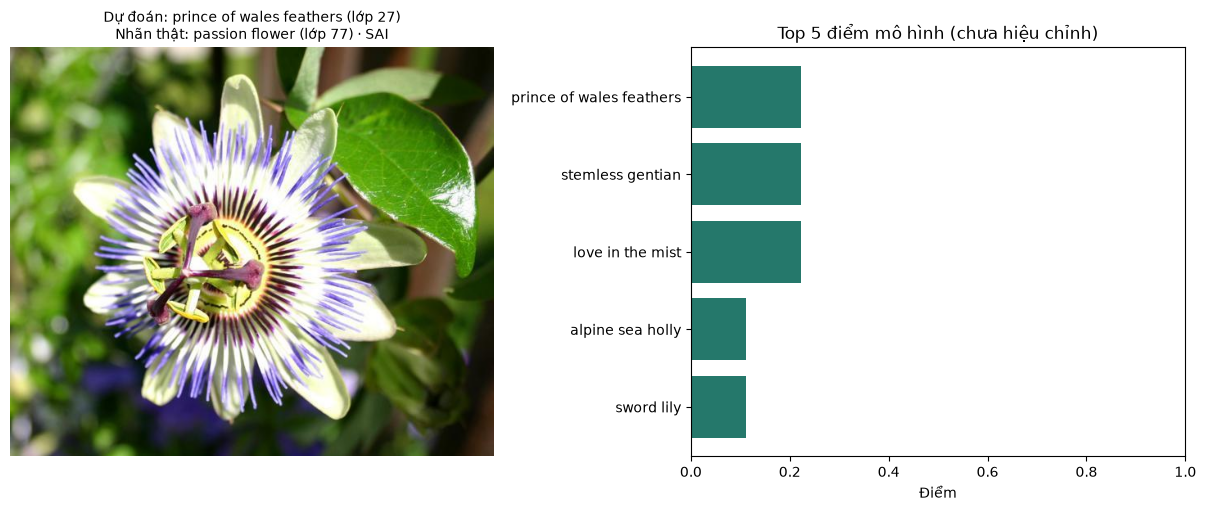

,label,flower,model_score
0,27,prince of wales feathers,0.222222
1,28,stemless gentian,0.222222
2,33,love in the mist,0.222222
3,35,alpine sea holly,0.111111
4,43,sword lily,0.111111


Đã lưu hình: outputs/20261117_160946_514913/demo_additional/figures/15_demo_test_00001.png


In [2]:
TEST_INDEX = 0
demo_result = demo_test_image(TEST_INDEX)

## Ví dụ dự đoán đúng
Chỉ số 30 ứng với ID 34. Có thể đổi chỉ số từ 0 đến 6144 để thử ảnh khác.

Ảnh thứ 30 trong 6145 ảnh test không trùng | image_id=34
Ảnh: data/jpg/image_00034.jpg
Mô hình: M8_HOG_HSV_KNN_tuned
Dự đoán: 77 — passion flower
Nhãn thật: 77 — passion flower | Kết quả: ĐÚNG


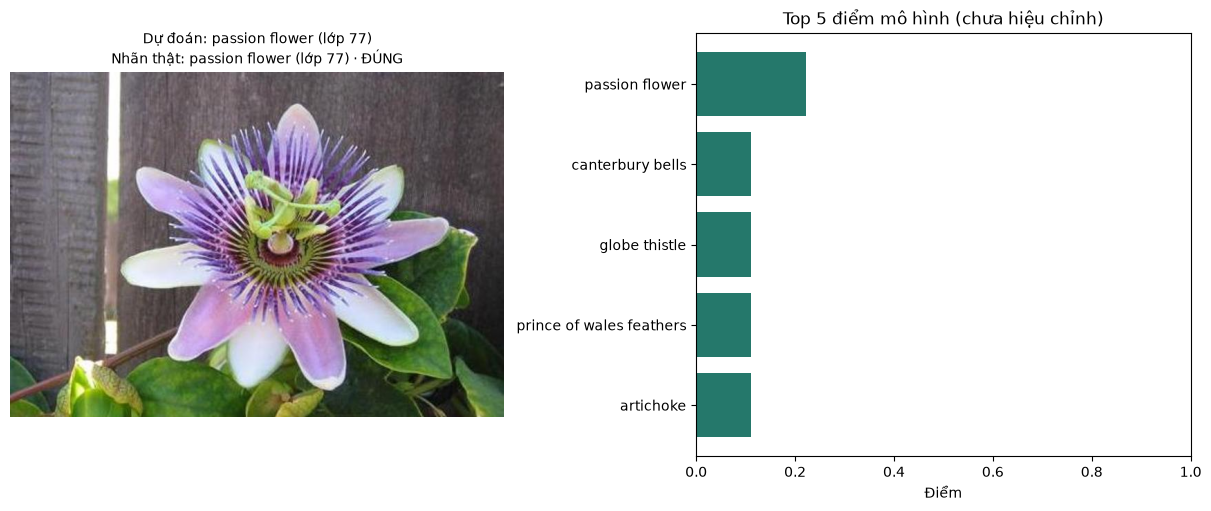

,label,flower,model_score
0,77,passion flower,0.222222
1,3,canterbury bells,0.111111
2,10,globe thistle,0.111111
3,27,prince of wales feathers,0.111111
4,29,artichoke,0.111111


Đã lưu hình: outputs/20261117_160946_514913/demo_additional/figures/15_demo_test_00034.png


In [3]:
TEST_INDEX = 30
demo_result = demo_test_image(TEST_INDEX)